# STEER on 2D Gaussian mixtures

This notebook trains small diffusion models on synthetic 2D Gaussian mixtures and compares STEER
(tempered score rescaling with replica exchange) against four baselines for sampling the tempered
target $p(x)^{1/\lambda}$:

| Benchmark | Distribution | $\lambda$ | Question |
|---|---|---|---|
| 1 | 19 clustered modes + 1 rare, sharp, isolated mode | 0.9 (sharpen) | Does the sampler reach the isolated mode? |
| 2 | 40 equal-weight modes | 0.9 (sharpen) | Are mode weights preserved? |

Everything runs on CPU. Total runtime is about 10 minutes on two CPU cores, most of it model training.

## Setup

In [1]:
# %pip install torch numpy scipy matplotlib pandas pot
import math
import sys
import time
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import ot
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch
from scipy.spatial.distance import cdist
from scipy.stats import gaussian_kde

try:
    import steer
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent))
    import steer
from steer import init_temp_idx, lambda_ladder, rescale, select_rung, swap

DEVICE = torch.device("cpu")
%matplotlib inline

### Plotting and metrics

In [2]:
_RED = "#b00000"
_CREAM = "#FAF5E7"
_BLACK = "#10151e"
_DARK_NAVY = "#283958"
_BLUE = "#3f5d94"
_LIGHT_BLUE = "#7289b3"
_LIGHT_GRAY = "#e1e4eb"

METHOD_LABELS = {"true": "True", "steer": "STEER", "crepe": "CREPE", "tsr": "TSR", "cns": "CNS", "mcmc": "MCMC"}
METHOD_COLORS = {"steer": "#1B5FAE", "crepe": "#C3A6D1", "tsr": "#C98686", "cns": "#97B3C6", "mcmc": "#a8b3a1"}

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "Liberation Serif", "DejaVu Serif", "Times"],
    "mathtext.fontset": "stix",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 150,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

_KDE_CMAP = LinearSegmentedColormap.from_list("topo", [_LIGHT_GRAY, _LIGHT_BLUE, _BLUE, _DARK_NAVY, _BLACK], N=256)


def make_rounded_subplots(nrows=1, ncols=1, *, figsize=None, panel_color="#EBEBEB", frame_color="#2B2B2B",
                          frame_lw=1.4, rounding=0.06, **subplots_kwargs):
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, **subplots_kwargs)
    patches = {}
    for ax in np.atleast_1d(axes).ravel():
        ax.set_facecolor("none")
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.tick_params(length=0)
        style = f"round,pad=0,rounding_size={rounding}"
        bg = FancyBboxPatch((0, 0), 1, 1, boxstyle=style, transform=ax.transAxes, facecolor=panel_color,
                            edgecolor="none", zorder=0, clip_on=False)
        frame = FancyBboxPatch((0, 0), 1, 1, boxstyle=style, transform=ax.transAxes, fill=False,
                               edgecolor=frame_color, linewidth=frame_lw, clip_on=False, zorder=10)
        ax.add_patch(bg)
        ax.add_patch(frame)
        patches[ax] = (bg, frame)

    def clip_to_panel(event):
        for ax, (bg, frame) in patches.items():
            for artist in ax.lines + ax.collections + ax.patches + ax.images:
                if artist is not bg and artist is not frame and artist.get_clip_path() is None:
                    artist.set_clip_path(bg)

    fig.canvas.mpl_connect("draw_event", clip_to_panel)
    return fig, axes


def plot_kde(ax, pts, hist_range, vmax, means, title, n_contours=6, dot_size=30):
    kde = gaussian_kde(pts.T, bw_method=0.15)
    xx, yy = np.meshgrid(np.linspace(*hist_range[0], 220), np.linspace(*hist_range[1], 220))
    density = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.pcolormesh(xx, yy, density, cmap=_KDE_CMAP, shading="gouraud", vmin=0.0, vmax=vmax, zorder=1)
    levels = np.linspace(0.0, vmax, n_contours + 2)[1:-1]
    ax.contour(xx, yy, density, levels=levels, colors=_CREAM, linewidths=0.5, alpha=0.5, zorder=2)
    ax.scatter(means[:, 0], means[:, 1], s=dot_size, marker="o", color=_RED, edgecolors=_CREAM,
               linewidths=0.5, zorder=5)
    ax.set_title(title, fontsize=25)
    ax.set_box_aspect(1)
    ax.set_xticks([])
    ax.set_yticks([])


def wasserstein2(x, y):
    a, b = np.full(len(x), 1.0 / len(x)), np.full(len(y), 1.0 / len(y))
    return float(np.sqrt(ot.emd2(a, b, cdist(x, y, "sqeuclidean"))))


def rbf_mmd2(x, y):
    pooled = np.vstack([x, y])
    d = cdist(pooled, pooled)
    sigma = max(np.median(d[d > 0]), 1e-6)
    kxx, kyy, kxy = (np.exp(-cdist(a, b, "sqeuclidean") / (2 * sigma ** 2)) for a, b in ((x, x), (y, y), (x, y)))
    np.fill_diagonal(kxx, 0.0)
    np.fill_diagonal(kyy, 0.0)
    m, n = len(x), len(y)
    return kxx.sum() / (m * (m - 1)) + kyy.sum() / (n * (n - 1)) - 2 * kxy.sum() / (m * n)


def nearest_mode(samples, means):
    return np.argmin(np.linalg.norm(samples[:, None, :] - means[None, :, :], axis=-1), axis=1)


def mode_coverage(samples, means, radius):
    dists = np.linalg.norm(samples[:, None, :] - means[None, :, :], axis=-1)
    return int((dists < radius).any(axis=0).sum())


def mode_occupancy_stats(samples, means, true_weights):
    empirical = np.bincount(nearest_mode(samples, means), minlength=len(means)) / len(samples)
    tv = 0.5 * np.abs(empirical - true_weights).sum()
    entropy = -np.sum(empirical * np.log(empirical + 1e-12)) / np.log(len(means))
    return tv, entropy

## 1. Model, data and samplers

### Target distributions

Each benchmark uses a mixture of isotropic Gaussians. The tempered target $p(x)^{1/\lambda}$ does not
factor over components, so reference samples are drawn exactly on a fine grid.

In [3]:
def true_tempered_sample(means, stds, weights, power, n, grid_size=800, pad_factor=10.0, rng=None):
    rng = rng if rng is not None else np.random.default_rng()
    means, stds, weights = (np.asarray(a, dtype=np.float64) for a in (means, stds, weights))
    pad = pad_factor * stds.max() / np.sqrt(min(power, 1.0))
    lo, hi = means.min(axis=0) - pad, means.max(axis=0) + pad
    xs, ys = np.linspace(lo[0], hi[0], grid_size), np.linspace(lo[1], hi[1], grid_size)
    xx, yy = np.meshgrid(xs, ys, indexing="ij")
    grid = np.stack([xx.ravel(), yy.ravel()], axis=-1)

    sq_dist = ((grid[:, None, :] - means[None, :, :]) ** 2).sum(axis=-1)
    log_mix = np.log(weights)[None] - np.log(2 * np.pi * stds ** 2)[None] - sq_dist / (2 * stds[None] ** 2)
    m = log_mix.max(axis=1, keepdims=True)
    log_p = power * (m.squeeze(-1) + np.log(np.exp(log_mix - m).sum(axis=1)))
    probs = np.exp(log_p - log_p.max())
    probs /= probs.sum()

    idx = rng.choice(len(probs), size=n, p=probs)
    jitter = rng.uniform(-0.5, 0.5, size=(n, 2)) * np.array([xs[1] - xs[0], ys[1] - ys[0]])
    return (grid[idx] + jitter).astype(np.float32)


class Mixture2D:
    def __init__(self, means, stds, weights, seed):
        self.means = means.astype(np.float32)
        self.stds = stds.astype(np.float32)
        self.weights = weights.astype(np.float32)
        self.num_modes = len(means)
        self._rng = np.random.default_rng(seed + 1)

    def sample(self, n, rng=None):
        rng = rng if rng is not None else self._rng
        idx = rng.choice(self.num_modes, size=n, p=self.weights)
        noise = rng.standard_normal(size=(n, 2)).astype(np.float32)
        return self.means[idx] + noise * self.stds[idx][:, None]

    def sample_batch(self, n, device="cpu"):
        return torch.from_numpy(self.sample(n)).to(device)

    def sample_true_tempered(self, n, power, rng=None):
        return true_tempered_sample(self.means, self.stds, self.weights, power, n, rng=rng)


def isolated_mode_mixture(num_modes=20, std=0.1, spread=5.0, seed=1, hard_weight=0.035,
                          hard_std_factor=0.08, hard_distance_factor=1.25):
    rng = np.random.default_rng(seed)
    easy = rng.uniform(-spread / 2, spread / 2, size=(num_modes - 1, 2))
    angle = rng.uniform(0.0, 2 * np.pi)
    hard = hard_distance_factor * spread * np.array([np.cos(angle), np.sin(angle)])
    means = np.concatenate([easy, hard[None]]).astype(np.float32)
    stds = np.array([std] * (num_modes - 1) + [std * hard_std_factor])
    weights = np.array([(1.0 - hard_weight) / (num_modes - 1)] * (num_modes - 1) + [hard_weight])
    return Mixture2D(means, stds, weights, seed)


def equal_weight_mixture(num_modes=40, std=0.1, spread=15.0, min_sep_factor=6.0, seed=1, max_tries=5000):
    rng = np.random.default_rng(seed)
    means = np.zeros((num_modes, 2), dtype=np.float32)
    means[0] = rng.uniform(-spread / 2, spread / 2, size=2)
    for i in range(1, num_modes):
        best, best_d = None, -1.0
        for _ in range(max_tries):
            cand = rng.uniform(-spread / 2, spread / 2, size=2)
            d = np.linalg.norm(means[:i] - cand[None], axis=1).min()
            if d >= min_sep_factor * std:
                best = cand
                break
            if d > best_d:
                best, best_d = cand, d
        means[i] = best
    return Mixture2D(means, np.full(num_modes, std), np.full(num_modes, 1.0 / num_modes), seed)

### Denoiser

A DDPM with a cosine schedule ($T = 100$) and a residual MLP noise predictor. All samplers share the
same trained model and differ only in the reverse process.

In [4]:
class DiffusionSchedule:
    def __init__(self, timesteps, s=0.008, max_beta=0.999, device="cpu"):
        self.timesteps = timesteps
        steps = torch.arange(timesteps + 1, dtype=torch.float64, device=device)
        f = torch.cos(((steps / timesteps) + s) / (1 + s) * math.pi / 2) ** 2
        alpha_bars = f / f[0]
        self.betas = torch.clamp(1 - alpha_bars[1:] / alpha_bars[:-1], min=1e-5, max=max_beta).float()
        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)
        self.sqrt_alpha_bars = torch.sqrt(self.alpha_bars)
        self.sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - self.alpha_bars)


class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device).float() / (half - 1))
        args = t.float().unsqueeze(-1) * freqs.unsqueeze(0)
        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)


class MLPDenoiser(nn.Module):
    def __init__(self, data_dim=2, hidden_dim=128, time_emb_dim=64, num_layers=4):
        super().__init__()
        self.time_embed = nn.Sequential(
            SinusoidalTimeEmbedding(time_emb_dim), nn.Linear(time_emb_dim, hidden_dim),
            nn.SiLU(), nn.Linear(hidden_dim, hidden_dim),
        )
        self.input_proj = nn.Linear(data_dim, hidden_dim)
        self.blocks = nn.ModuleList(
            [nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.SiLU()) for _ in range(num_layers)]
        )
        self.output_proj = nn.Linear(hidden_dim, data_dim)

    def forward(self, x, t):
        h = self.input_proj(x) + self.time_embed(t)
        for block in self.blocks:
            h = h + block(h)
        return self.output_proj(h)


def train_denoiser(dataset, schedule, steps, seed=1, hidden_dim=128, num_layers=4, batch_size=256, lr=2e-4,
                   log_every=2000):
    torch.manual_seed(seed)
    model = MLPDenoiser(hidden_dim=hidden_dim, num_layers=num_layers).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for step in range(1, steps + 1):
        x0 = dataset.sample_batch(batch_size, device=DEVICE)
        t = torch.randint(0, schedule.timesteps, (batch_size,), device=DEVICE)
        noise = torch.randn_like(x0)
        x_t = schedule.sqrt_alpha_bars[t].unsqueeze(-1) * x0 + schedule.sqrt_one_minus_alpha_bars[t].unsqueeze(-1) * noise
        loss = F.mse_loss(model(x_t, t), noise)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if step % log_every == 0:
            print(f"step {step:5d}/{steps}  loss {loss.item():.4f}")
    return model.eval()


schedule = DiffusionSchedule(100, device=DEVICE)

### Samplers

$\lambda < 1$ sharpens the target and $\lambda > 1$ broadens it.

- **STEER**: `n_replicas` chains on a linear ladder from `lam_start` to `lam_end`. At every step,
  neighbouring rungs propose to exchange temperatures with a Metropolis test, then each chain's
  noise prediction is rescaled for its current rung. The output is the chain holding `lam_start`.
- **TSR**: the same rescaling with a single chain at `lam_start` and no swaps.
- **CNS**: scales the injected noise by $\sqrt{\lambda}$ instead of rescaling the score.
- **MCMC**: annealed Langevin corrector steps on the tempered score at every noise level.
- **CREPE**: parallel tempering across diffusion time, initialised from untempered ancestral samples.

In [5]:
MCMC_STEPS = 10
MCMC_STEP_SIZE = 1e-3


@torch.no_grad()
def ddpm_sample(model, schedule, num_samples, n_replicas, lam_start, lam_end, method, generator=None, rung=0):
    device = schedule.betas.device
    total = n_replicas * num_samples
    x = torch.randn(total, 2, device=device, generator=generator)
    temp_idx = init_temp_idx(n_replicas, num_samples, device=device)
    lam_ladder = lambda_ladder(lam_start, lam_end, n_replicas, device=device)

    for t_index in reversed(range(schedule.timesteps)):
        t = torch.full((total,), t_index, device=device, dtype=torch.long)
        beta_t, alpha_t, alpha_bar_t = schedule.betas[t_index], schedule.alphas[t_index], schedule.alpha_bars[t_index]

        if method == "mcmc":
            for _ in range(MCMC_STEPS):
                score = -model(x, t) / torch.sqrt(1.0 - alpha_bar_t)
                z = torch.randn(x.shape, device=device, generator=generator)
                x = x + MCMC_STEP_SIZE * score / lam_start + math.sqrt(2.0 * MCMC_STEP_SIZE) * z

        eps = model(x, t)
        if method == "steer":
            score = -eps / torch.sqrt(torch.clamp(1 - alpha_bar_t, min=1e-3))
            swap(x, score, alpha_bar_t, lam_ladder, temp_idx, t_index, generator=generator)
        if method in ("steer", "tsr"):
            eps = rescale(eps, alpha_bar_t, lam_ladder, temp_idx)

        coef = beta_t / torch.sqrt(1.0 - alpha_bar_t)
        mean = (x - coef * eps) / torch.sqrt(alpha_t)
        if t_index > 0:
            z = torch.randn(x.shape, device=device, generator=generator)
            if method == "cns":
                z = z * math.sqrt(lam_start)
            x = mean + torch.sqrt(beta_t) * z
        else:
            x = mean

    return select_rung(x, temp_idx, rung)

In [6]:
def _log_normal(x, mu, std):
    std = std.expand(x.shape)
    return -0.5 * ((x - mu) / std).pow(2).sum(dim=-1) - (torch.log(std) + math.log(2 * math.pi) / 2).sum(dim=-1)


def _sigma_schedule(T, device, sigma_min=0.002, sigma_max=80.0, rho=7.0, lam_start=1.0):
    sigma_min = sigma_min * math.sqrt(lam_start)
    t = torch.linspace(0, 1, T, device=device)
    return (sigma_max ** (1 / rho) + t * (sigma_min ** (1 / rho) - sigma_max ** (1 / rho))).pow(rho)


def _denoised(model, y, t_idx, schedule):
    a = schedule.alpha_bars[t_idx].view(1, -1, 1)
    x = y * torch.sqrt(a)
    B, K, D = x.shape
    eps = model(x.reshape(B * K, D), t_idx.unsqueeze(0).expand(B, K).reshape(B * K)).reshape(B, K, D)
    return (x - torch.sqrt(1 - a) * eps) / torch.sqrt(a)


@torch.no_grad()
def crepe_sweep(ys, sigmas, model, schedule, parity, generator=None):
    B, T, D = ys.shape
    device = ys.device
    t_idx = (T - 1) - torch.arange(T, device=device)
    ys[:, 0] = sigmas[0] * torch.randn(ys[:, 0].shape, device=device, generator=generator)

    idx1 = torch.arange(T, device=device)[parity:-1:2]
    idx0 = torch.arange(T, device=device)[parity + 1::2]
    s1, s0 = sigmas[idx1].view(1, -1, 1), sigmas[idx0].view(1, -1, 1)
    dt = (s1 - s0).abs()
    bwd_std, fwd_std = torch.sqrt(2 * s1 * dt), torch.sqrt(2 * s0 * dt)
    x1, x0 = ys[:, idx1], ys[:, idx0]

    score1 = (_denoised(model, x1, t_idx[idx1], schedule) - x1) / s1 ** 2
    x0_cand = x1 + bwd_std ** 2 * score1 + bwd_std * torch.randn(x1.shape, device=device, generator=generator)
    log_w = _log_normal(x1, x0_cand, fwd_std) - _log_normal(x0_cand, x1 + bwd_std ** 2 * score1, bwd_std)

    x1_cand = x0 + fwd_std * torch.randn(x0.shape, device=device, generator=generator)
    score1b = (_denoised(model, x1_cand, t_idx[idx1], schedule) - x1_cand) / s1 ** 2
    log_w -= _log_normal(x1_cand, x0, fwd_std) - _log_normal(x0, x1_cand + bwd_std ** 2 * score1b, bwd_std)

    accept = (torch.rand(log_w.shape, device=device, generator=generator).log() < log_w).unsqueeze(-1)
    ys[:, idx1] = torch.where(accept, x1_cand, x1)
    ys[:, idx0] = torch.where(accept, x0_cand, x0)
    return ys


@torch.no_grad()
def crepe_sample(model, schedule, num_samples, n_sweeps, lam_start=1.0, generator=None):
    device = schedule.betas.device
    T = schedule.timesteps
    sigmas = _sigma_schedule(T, device, lam_start=lam_start)
    x0 = ddpm_sample(model, schedule, num_samples, 1, 1.0, 1.0, "vanilla", generator=generator)
    ys = x0.unsqueeze(1) + sigmas.view(1, T, 1) * torch.randn(num_samples, T, 2, device=device, generator=generator)
    for _ in range(n_sweeps):
        for parity in (0, 1):
            ys = crepe_sweep(ys, sigmas, model, schedule, parity, generator=generator)
    return ys[:, -1] * torch.sqrt(schedule.alpha_bars[0])

### Experiment harness

Each method is run for five seeds with 1000 samples per seed. For STEER the replica count is the
ladder size; for CREPE it is the number of parallel-tempering sweeps. The `true` row draws exact
samples from the tempered target with an independent seed and gives the finite-sample noise floor
for every metric.

In [7]:
SEEDS = [1, 50, 100, 150, 200]
NUM_SAMPLES = 1000
METHODS = ["true", "steer", "crepe", "tsr", "cns", "mcmc"]


def generate_samples(model, method, n_replicas, seed, lam_start, lam_end, num_samples=NUM_SAMPLES):
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    if method == "crepe":
        out = crepe_sample(model, schedule, num_samples, n_replicas, lam_start=lam_start, generator=generator)
    else:
        out = ddpm_sample(model, schedule, num_samples, n_replicas, lam_start, lam_end, method,
                          generator=generator)
    return out.cpu().numpy()


def run_benchmark(model, dataset, replicas, lam_start, lam_end):
    samples = {}
    for method in METHODS:
        t0 = time.perf_counter()
        for seed in SEEDS:
            if method == "true":
                rng = np.random.default_rng(seed + 10_000)
                samples[method, seed] = dataset.sample_true_tempered(NUM_SAMPLES, 1.0 / lam_start, rng=rng)
            else:
                samples[method, seed] = generate_samples(model, method, replicas.get(method, 1), seed,
                                                         lam_start, lam_end)
        print(f"{method:6s} {time.perf_counter() - t0:6.1f}s")
    return samples


def evaluate(samples, dataset, lam_start, radius, hard_mode=None):
    true_weights = np.bincount(
        nearest_mode(dataset.sample_true_tempered(20_000, 1.0 / lam_start, rng=np.random.default_rng(0)), dataset.means),
        minlength=dataset.num_modes,
    ) / 20_000
    rows = []
    for (method, seed), gen in samples.items():
        ref = dataset.sample_true_tempered(len(gen), 1.0 / lam_start, rng=np.random.default_rng(seed))
        tv, entropy = mode_occupancy_stats(gen, dataset.means, true_weights)
        row = dict(method=method, seed=seed, wasserstein2=wasserstein2(ref, gen), mmd2_rbf=rbf_mmd2(ref, gen),
                   modes_covered=mode_coverage(gen, dataset.means, radius), mode_weight_tv=tv,
                   entropy_normalized=entropy)
        if hard_mode is not None:
            row["hard_mode_hits"] = int((np.linalg.norm(gen - hard_mode, axis=1) < radius).sum())
        rows.append(row)
    df = pd.DataFrame(rows).drop(columns="seed")
    agg = df.groupby("method").agg(["mean", "sem"]).reindex(METHODS)
    agg.columns = [f"{metric}_{stat}" for metric, stat in agg.columns]
    return agg


METRIC_PANELS = [
    ("wasserstein2", r"W2 ($\downarrow$ better)", "Distance to target", ".2f"),
    ("mmd2_rbf", r"MMD$^2$ ($\downarrow$ better)", "Kernel discrepancy", ".4f"),
    ("mode_weight_tv", r"TV error ($\downarrow$ better)", "Mode-weight balance", ".3f"),
    ("entropy_normalized", r"entropy ($\uparrow$ better)", "Occupancy entropy", ".3f"),
    ("modes_covered", r"modes ($\uparrow$ better)", "Mode coverage", ".1f"),
    ("hard_mode_hits", r"hits ($\uparrow$ better)", "Isolated-mode hits", ".1f"),
]


def plot_bars(agg, ncols=3):
    methods = METHODS[1:]
    sub = agg.reindex(methods)
    labels = [METHOD_LABELS[m] for m in methods]
    colors = [METHOD_COLORS[m] for m in methods]
    panels = [p for p in METRIC_PANELS if f"{p[0]}_mean" in agg.columns]
    nrows = math.ceil(len(panels) / ncols)
    fig, axes = make_rounded_subplots(nrows, ncols, figsize=(4.6 * ncols, 3.8 * nrows), panel_color="#F4F4F4",
                                      frame_lw=1.2, rounding=0.05)
    axes = np.atleast_1d(axes).ravel()
    for ax, (metric, ylabel, title, fmt) in zip(axes, panels):
        mean, sem = sub[f"{metric}_mean"], sub[f"{metric}_sem"]
        ref = agg.loc["true", f"{metric}_mean"]
        lo, hi = min((mean - sem).min(), ref), max((mean + sem).max(), ref)
        bottom = lo - 0.6 * (hi - lo) if lo > 0.5 * hi else 0.0
        top = hi + 0.3 * (hi - bottom)
        ax.bar(labels, mean, yerr=sem, color=colors, width=0.65, capsize=4,
               error_kw=dict(elinewidth=1.4, ecolor="#2B2B2B"), edgecolor="#2B2B2B", linewidth=0.8, zorder=3)
        for i, (m, s) in enumerate(zip(mean, sem)):
            ax.text(i, m + s + 0.03 * (top - bottom), format(m, fmt), ha="center", va="bottom", fontsize=12)
        ax.axhline(ref, color="#2B2B2B", linestyle="--", linewidth=1.2, zorder=4, label=f"True ({ref:{fmt}})")
        ax.legend(fontsize=11, frameon=False, loc="upper right")
        ax.set_ylim(bottom, top)
        ax.set_ylabel(ylabel, fontsize=13)
        ax.set_title(title, fontsize=17)
        ax.set_yticks([])
        ax.tick_params(axis="x", labelsize=11)
    for ax in axes[len(panels):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()


def plot_densities(samples, dataset, hist_range, vmax, n_contours):
    fig, axes = make_rounded_subplots(1, len(METHODS), figsize=(19, 5.0), panel_color="#FFFFFF",
                                      frame_color=_DARK_NAVY, frame_lw=1.8, rounding=0.04, sharex=True, sharey=True)
    for ax, method in zip(axes, METHODS):
        pts = np.concatenate([samples[method, seed] for seed in SEEDS])
        plot_kde(ax, pts, hist_range, vmax, dataset.means, METHOD_LABELS[method].upper(), n_contours=n_contours)
    plt.tight_layout()
    plt.show()


def padded_range(dataset, pad):
    lo, hi = dataset.means.min(axis=0) - pad, dataset.means.max(axis=0) + pad
    return [[lo[0], hi[0]], [lo[1], hi[1]]]

## 2. Benchmark 1: an isolated mode

Nineteen modes are placed uniformly in a $5 \times 5$ square around the origin. A twentieth mode sits
outside the square with 3.5% of the mass and a much smaller width, so it has the highest peak density
in the mixture. Reverse trajectories started from $\mathcal{N}(0, I)$ pass through the cluster and
rarely reach the isolated mode.

In [8]:
dataset = isolated_mode_mixture()
hard_mode = dataset.means[-1]
model_isolated = train_denoiser(dataset, schedule, steps=10_000)

step  2000/10000  loss 0.4479


step  4000/10000  loss 0.4342


step  6000/10000  loss 0.4650


step  8000/10000  loss 0.4268


step 10000/10000  loss 0.4041


Target $\lambda = 0.9$. STEER uses four replicas on the ladder $0.9 \to 20.0$; TSR, CNS and MCMC run a
single chain at $\lambda = 0.9$. A sample counts as a hit if it lies within 0.5 of the isolated mode.

In [9]:
LAM_START, LAM_END = 0.9, 20.0
samples_isolated = run_benchmark(model_isolated, dataset, {"steer": 4, "crepe": 4}, LAM_START, LAM_END)
agg_isolated = evaluate(samples_isolated, dataset, LAM_START, radius=0.5, hard_mode=hard_mode)
agg_isolated

true      3.7s


steer     3.2s


crepe     8.7s


tsr       0.8s


cns       0.8s


mcmc      8.4s


,wasserstein2_mean,wasserstein2_sem,mmd2_rbf_mean,mmd2_rbf_sem,modes_covered_mean,modes_covered_sem,mode_weight_tv_mean,mode_weight_tv_sem,entropy_normalized_mean,entropy_normalized_sem,hard_mode_hits_mean,hard_mode_hits_sem
method,,,,,,,,,,,,
true,0.572923,0.046179,0.000671,0.000485,20.0,0.0,0.06843,0.005026,0.995451,0.000590,57.6,4.610857
steer,0.614536,0.054069,0.001379,0.000948,20.0,0.0,0.08394,0.004818,0.991059,0.000610,62.8,1.392839
crepe,0.737393,0.045965,0.001587,0.000249,20.0,0.0,0.10984,0.004248,0.987675,0.000819,28.2,3.277194
tsr,0.762693,0.042046,0.001854,0.000221,20.0,0.0,0.11802,0.004669,0.985969,0.000755,26.6,2.657066
cns,0.812080,0.031599,0.002353,0.000318,20.0,0.0,0.11807,0.004111,0.985911,0.000899,22.0,2.607681
mcmc,0.887610,0.015315,0.003383,0.000609,20.0,0.0,0.21062,0.003393,0.950833,0.001938,21.2,3.072458


/tmp/ipykernel_1885511/603081337.py:84: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(bottom, top)


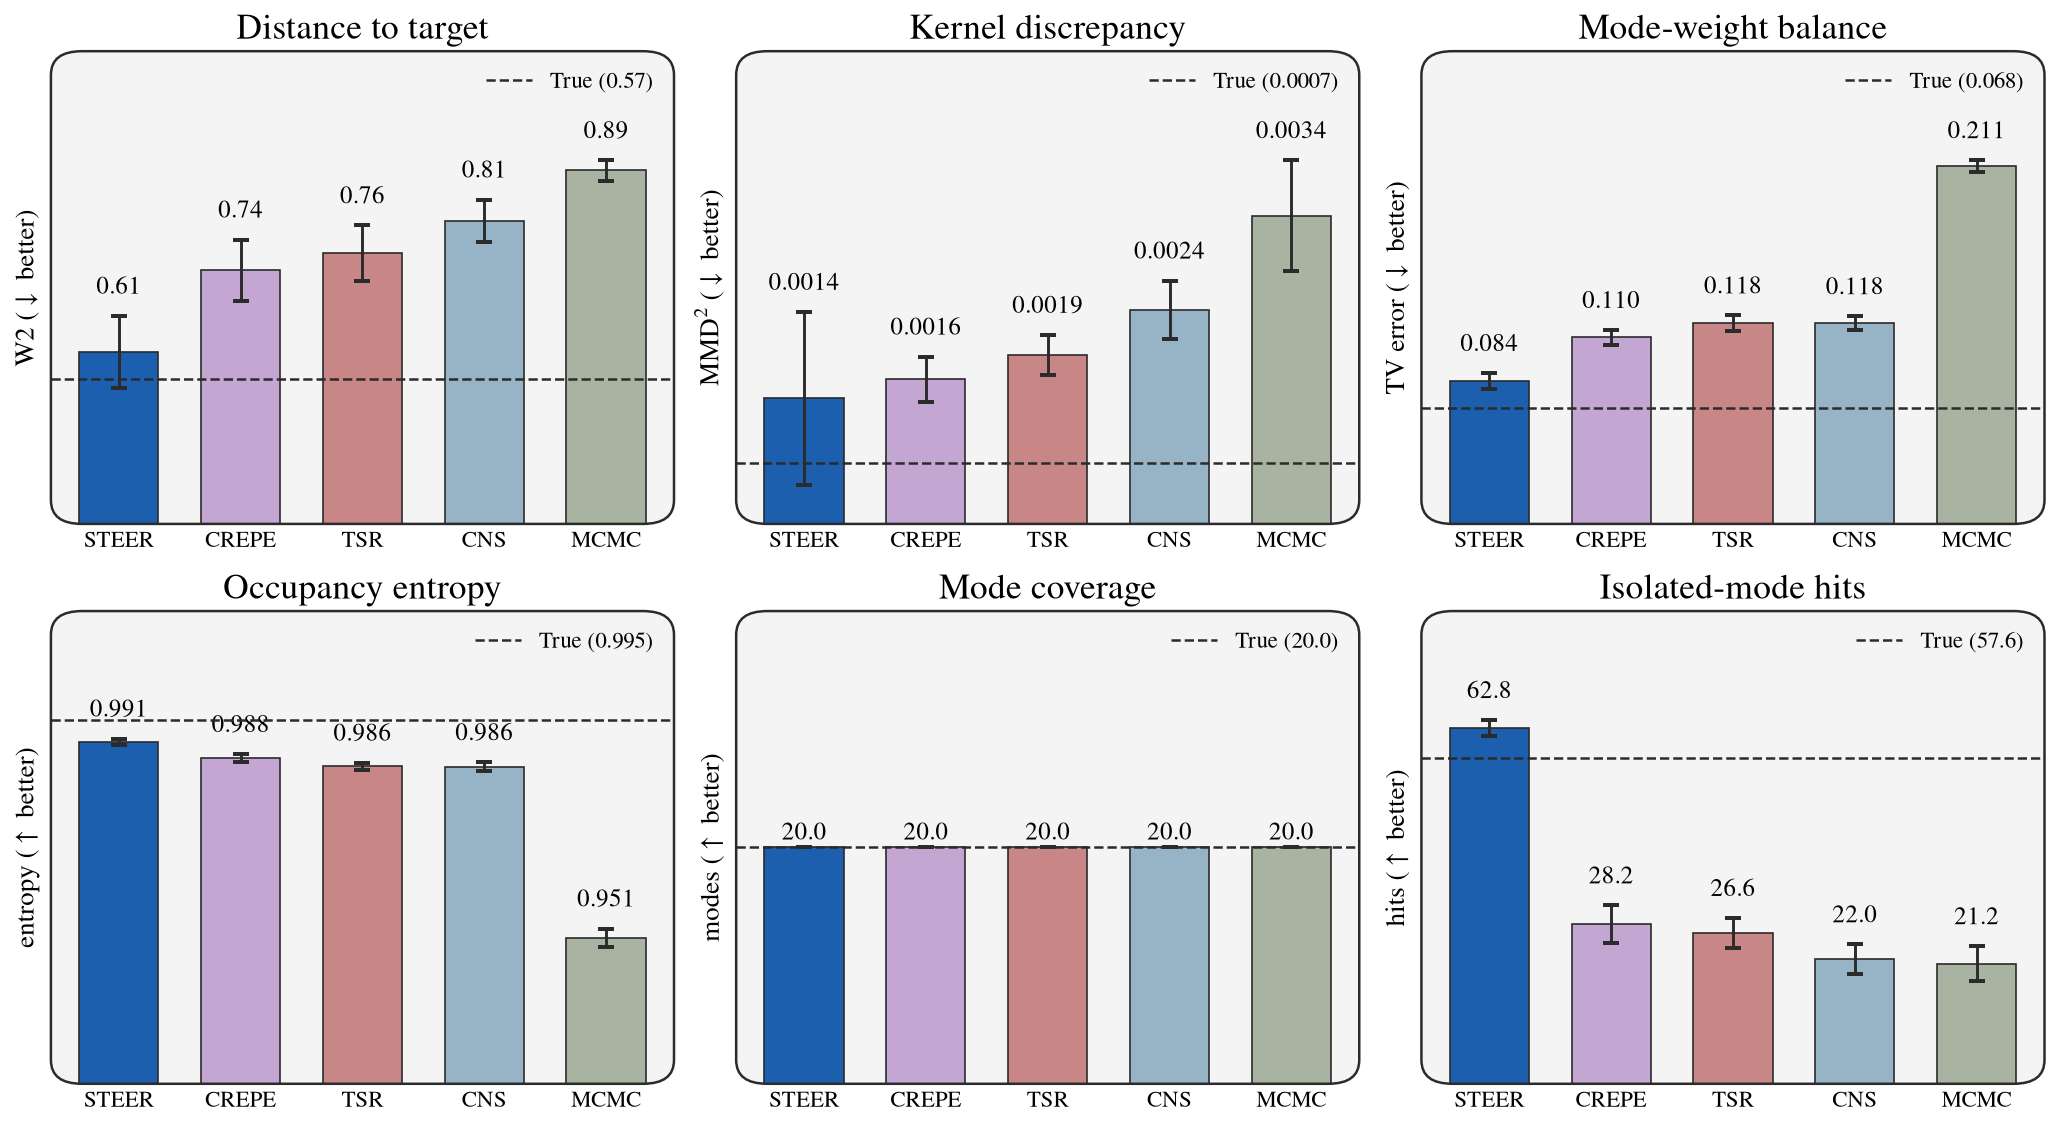

In [10]:
plot_bars(agg_isolated)

Sample densities pooled over all seeds (dots mark mode centres):

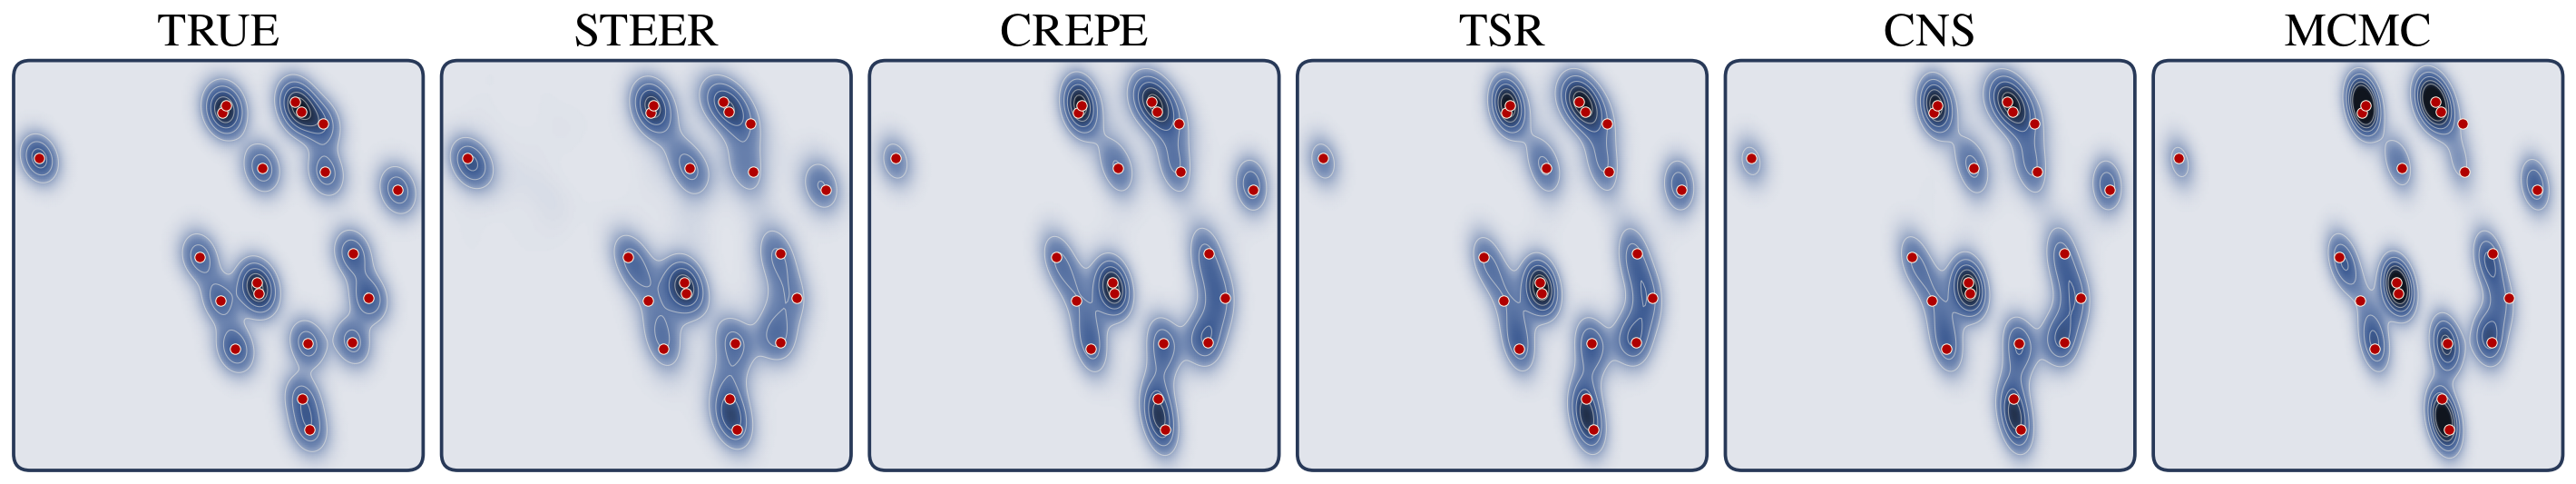

In [11]:
hist_range = padded_range(dataset, 6.0 * 0.1)
plot_densities(samples_isolated, dataset, hist_range, vmax=0.25, n_contours=5)

## 3. Benchmark 2: mode weights under sharpening

Forty Gaussians with equal width and weight are placed in a $15 \times 15$ square with a minimum
separation of six standard deviations. Tempering a mixture of identical, well-separated components
leaves the weights uniform, so the target occupancy is $1/40$ per mode for every $\lambda$.

In [12]:
dataset_mm = equal_weight_mixture()
model_mm = train_denoiser(dataset_mm, schedule, steps=20_000)

step  2000/20000  loss 0.7547


step  4000/20000  loss 0.5550


step  6000/20000  loss 0.5635


step  8000/20000  loss 0.5534


step 10000/20000  loss 0.6551


step 12000/20000  loss 0.5722


step 14000/20000  loss 0.5521


step 16000/20000  loss 0.6004


step 18000/20000  loss 0.5616


step 20000/20000  loss 0.5206


Target $\lambda = 0.9$ with the ladder $0.9 \to 4.0$ with three STEER replicas. Coverage counts modes
with at least one sample within 0.3 of the centre.

In [13]:
LAM_START_MM, LAM_END_MM = 0.9, 4.0
samples_mm = run_benchmark(model_mm, dataset_mm, {"steer": 3, "crepe": 3}, LAM_START_MM, LAM_END_MM)
agg_mm = evaluate(samples_mm, dataset_mm, LAM_START_MM, radius=0.3)
agg_mm

true      7.0s


steer     2.6s


crepe     6.9s


tsr       0.8s


cns       0.8s


mcmc      8.4s


,wasserstein2_mean,wasserstein2_sem,mmd2_rbf_mean,mmd2_rbf_sem,modes_covered_mean,modes_covered_sem,mode_weight_tv_mean,mode_weight_tv_sem,entropy_normalized_mean,entropy_normalized_sem
method,,,,,,,,,,
true,1.157749,0.101342,0.001392,0.000633,40.0,0.000000,0.08490,0.004952,0.994509,0.000528
steer,1.244221,0.057029,0.001429,0.000598,40.0,0.000000,0.14565,0.006188,0.982040,0.001755
crepe,1.405290,0.096583,0.003026,0.001025,39.4,0.244949,0.15672,0.005107,0.979173,0.001585
tsr,1.406611,0.094301,0.002885,0.001003,39.4,0.244949,0.16261,0.006495,0.977348,0.001926
cns,1.391246,0.092758,0.002725,0.000946,39.8,0.200000,0.15546,0.004097,0.978752,0.001286
mcmc,1.445679,0.042319,0.002732,0.000576,38.0,0.316228,0.22782,0.006050,0.951526,0.002353


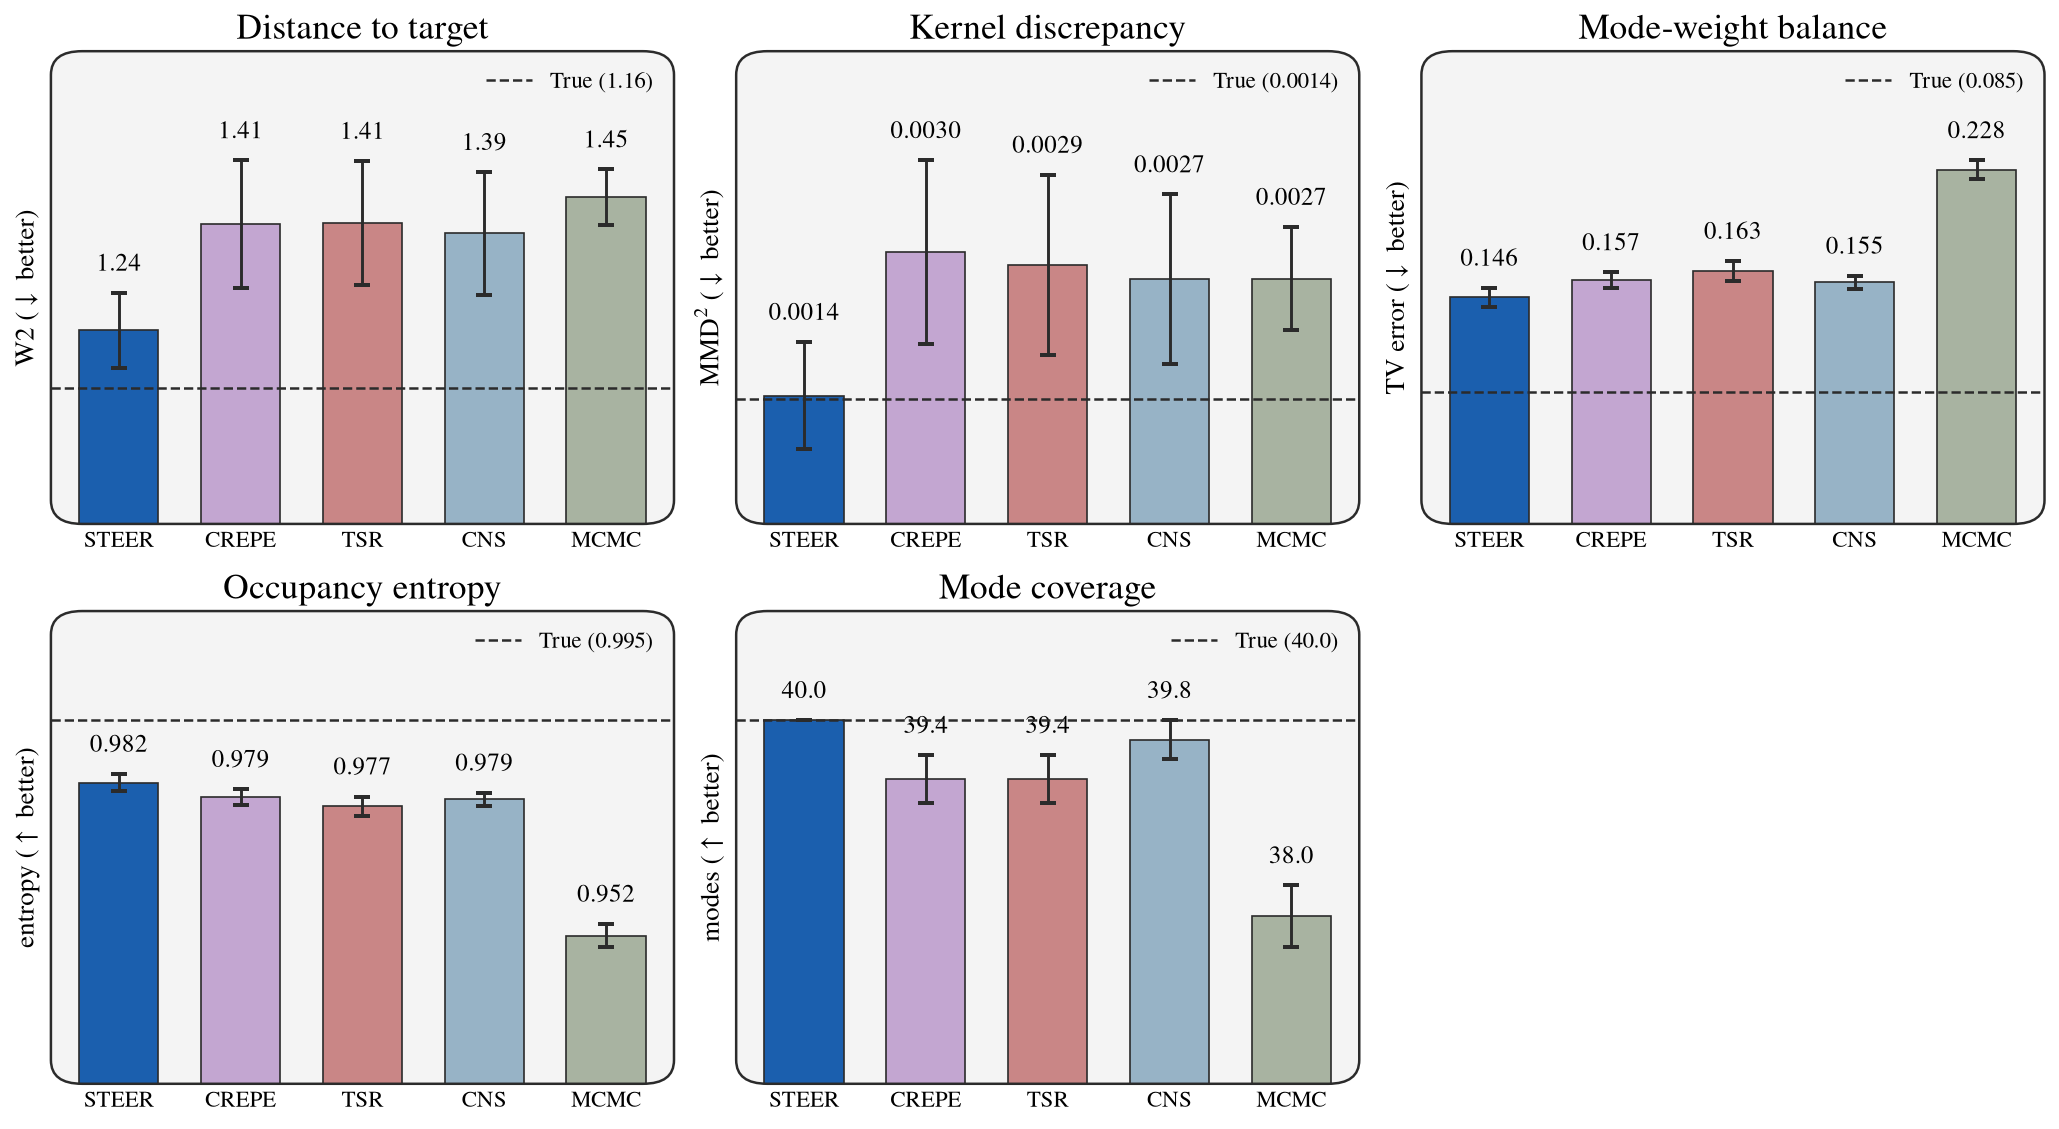

In [14]:
plot_bars(agg_mm)

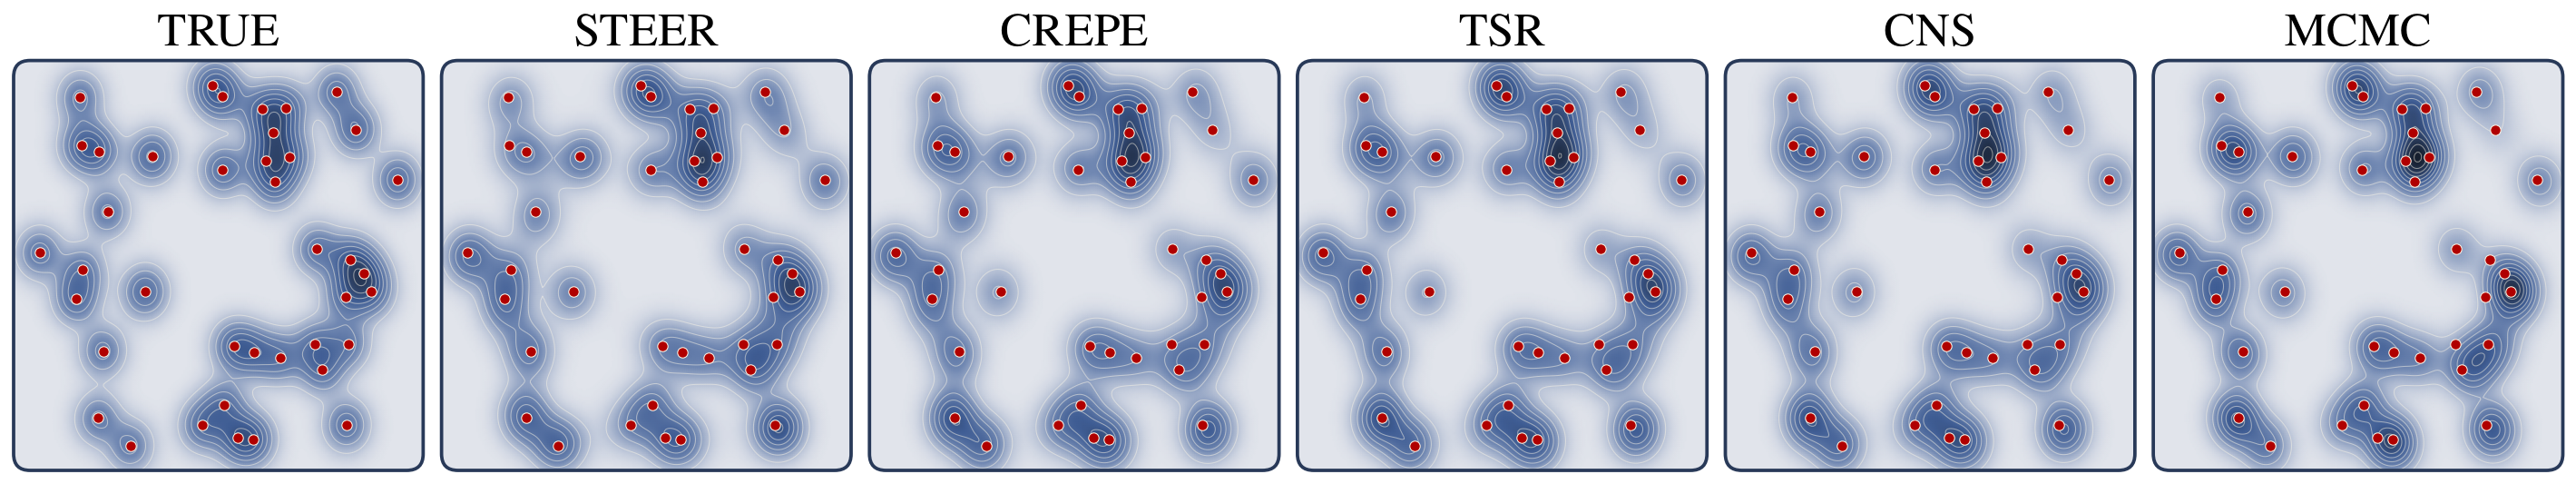

In [15]:
hist_range_mm = padded_range(dataset_mm, 10.0 * 0.1)
plot_densities(samples_mm, dataset_mm, hist_range_mm, vmax=0.03, n_contours=10)